# BijliPredict AI - Exploration

Lightweight EDA for the daily household electricity consumption series.
Run the pipeline first: `python generate_data.py` (or `python iawe_ingest.py`).

In [67]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Allow importing top-level project modules from the notebook, whether it
# is launched from the project root or from the notebooks/ directory.
for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / "preprocessing.py").exists():
        sys.path.append(str(_p))
        break
from preprocessing import clean_series, load_consumption

plt.rcParams["figure.figsize"] = (12, 4)
pd.set_option("display.width", 120)

## 1. Load and clean

In [68]:
DATA = "../data/processed/daily_consumption.csv"
series = clean_series(load_consumption(DATA))
series.describe()

,consumption_kwh
count,1369.000000
mean,5.451718
std,1.451262
min,0.942000
25%,4.489000
50%,5.509000
75%,6.524000
max,9.639000


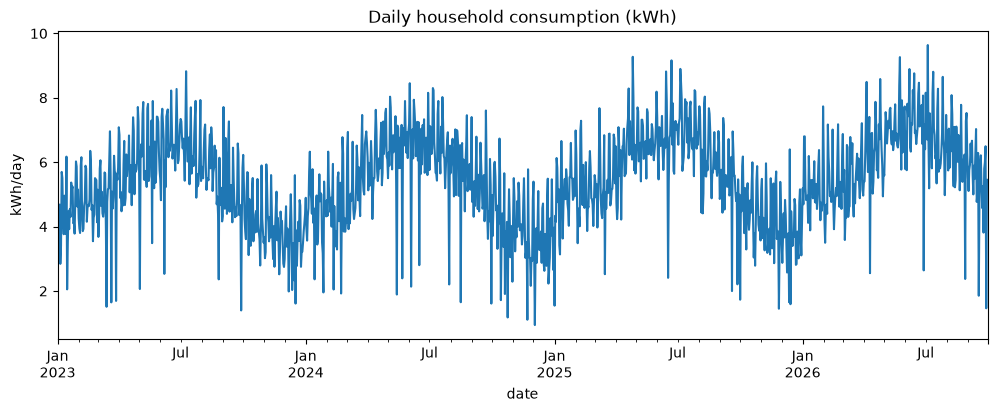

In [69]:
series["consumption_kwh"].plot(title="Daily household consumption (kWh)")
plt.ylabel("kWh/day")
plt.show()

## 2. Weekly pattern

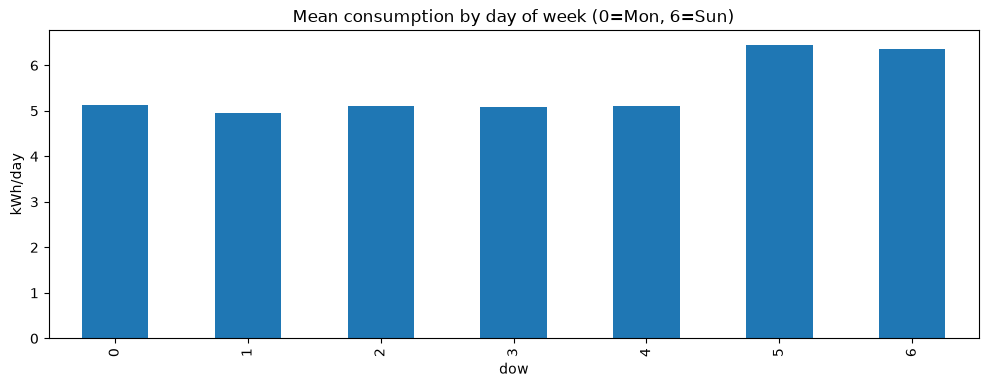

In [70]:
df = series.copy()
df["dow"] = df.index.dayofweek
df.groupby("dow")["consumption_kwh"].mean().plot(
    kind="bar", title="Mean consumption by day of week (0=Mon, 6=Sun)"
)
plt.ylabel("kWh/day")
plt.show()

## 3. Annual / monthly pattern

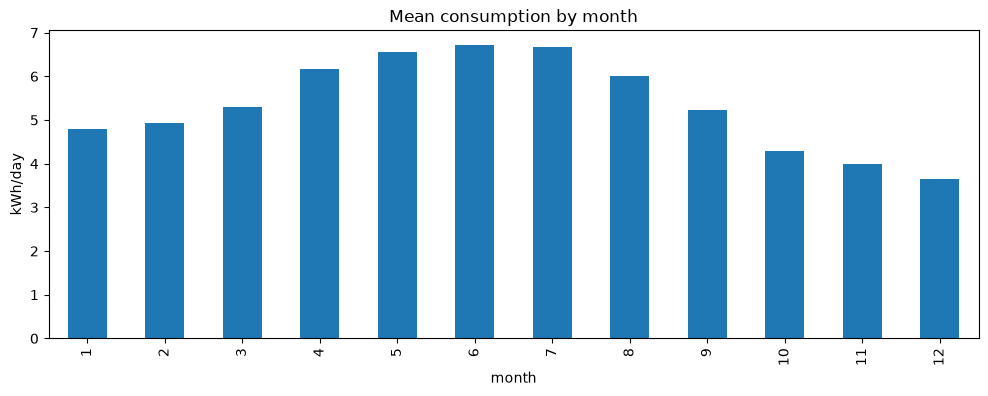

In [71]:
df["month"] = df.index.month
df.groupby("month")["consumption_kwh"].mean().plot(
    kind="bar", title="Mean consumption by month"
)
plt.ylabel("kWh/day")
plt.show()

## 4. Missingness / gaps in the source file

In [72]:
raw = load_consumption(DATA)
expected = pd.date_range(raw.index.min(), raw.index.max(), freq="D")
print("rows:", len(raw), " expected daily:", len(expected), " missing:", len(expected) - len(raw))
print("min/max:", float(raw["consumption_kwh"].min()), float(raw["consumption_kwh"].max()))

rows: 1369  expected daily: 1369  missing: 0
min/max: 0.942 9.639


## 5. Trained model results

After running `python train.py` and `python evaluate.py`, inspect the saved
metrics and plot.

{
  "mae": 0.6906462513098196,
  "rmse": 0.9678841821051819,
  "wape": 10.568245776248828,
  "mape": 13.250318122737442
}
vs seasonal-naive: {'mae': 0.913358810569058, 'rmse': 1.2477515284762684, 'wape': 13.976185889215815, 'mape': 17.0834264098188}


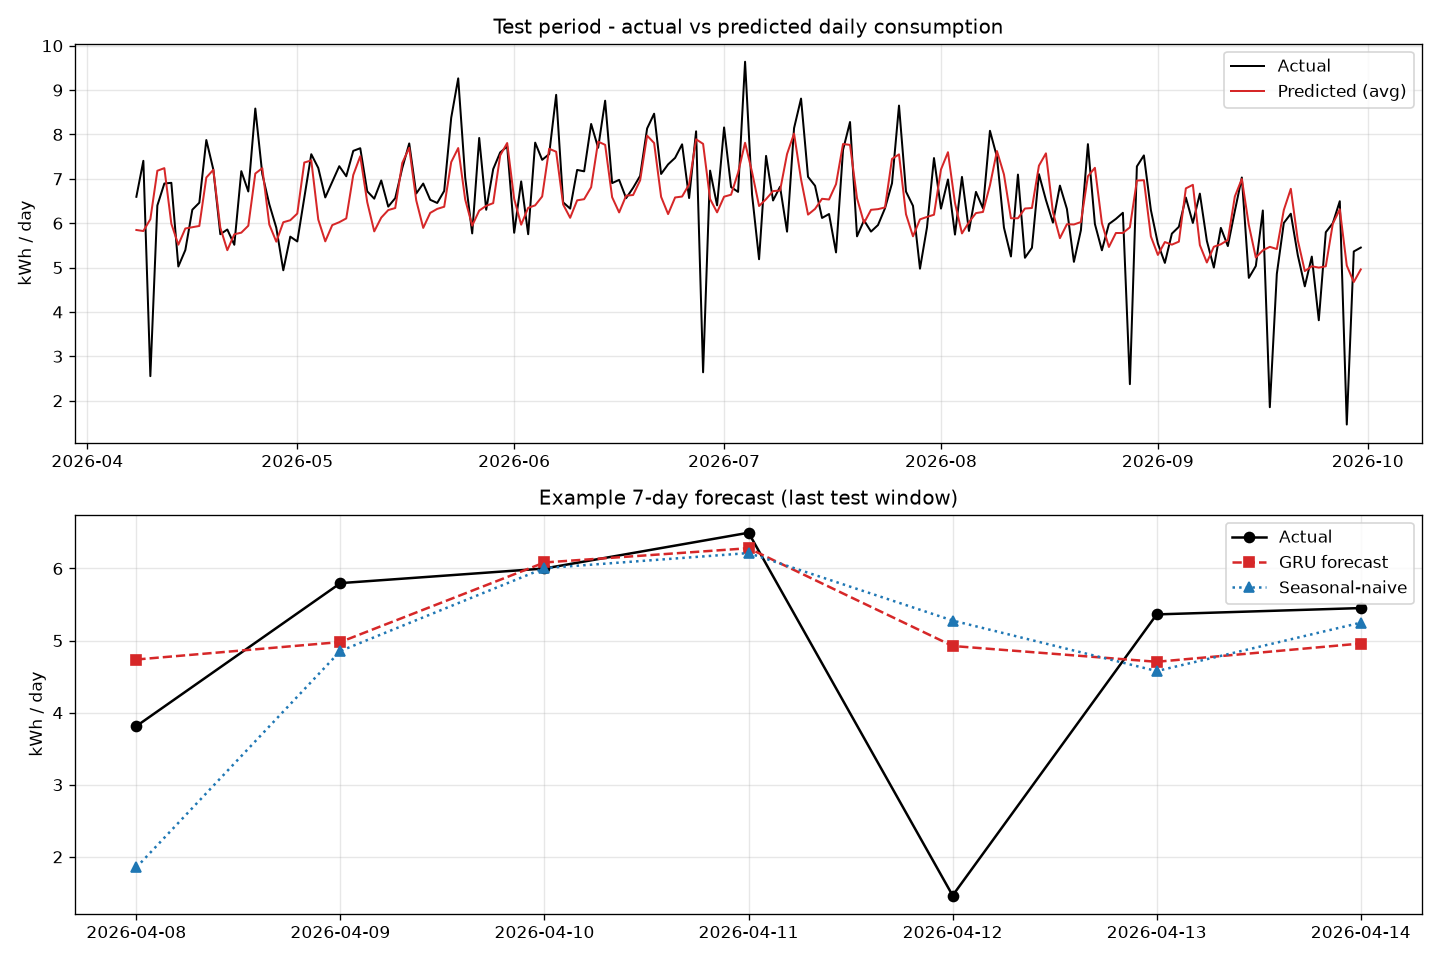

In [73]:
import json
from IPython.display import Image

results = json.loads(Path("../outputs/evaluation.json").read_text())
print(json.dumps(results["model_metrics"], indent=2))
print("vs seasonal-naive:", results["baseline_metrics"]["seasonal_naive_p7"])
Image(filename="../outputs/forecast.png")

## 6. Forecast and cost prediction

`predict.py` forecasts the next 7 days of consumption and converts them to a
bill using the `tariffs.py` module (flat rate or progressive Indian slabs,
plus optional fixed charge and tax). Run `python predict.py` first so the
files below exist.

In [74]:
from IPython.display import Image

cost = json.loads(Path("../outputs/cost_summary.json").read_text())
print("Tariff:", cost["tariff"])
print(f"Forecast : {cost['total_kwh']} kWh over {cost['forecast_days']} days")
print(f"Energy   : Rs {cost['energy_charge_inr']}")
print(f"Tax      : Rs {cost['tax_inr']}")
print(f"Fixed    : Rs {cost['fixed_charge_inr']}")
print(f"TOTAL    : Rs {cost['estimated_bill_inr']}")
pd.DataFrame(cost["daily"])

Tariff: ₹7/kWh (flat)
Forecast : 35.049 kWh over 7 days
Energy   : Rs 245.34
Tax      : Rs 0.0
Fixed    : Rs 0.0
TOTAL    : Rs 245.34


,date,kwh,cost_inr
0,2026-10-01,4.417,30.92
1,2026-10-02,4.870,34.09
2,2026-10-03,6.087,42.61
3,2026-10-04,5.931,41.52
4,2026-10-05,4.606,32.24
5,2026-10-06,4.425,30.97
6,2026-10-07,4.712,32.98


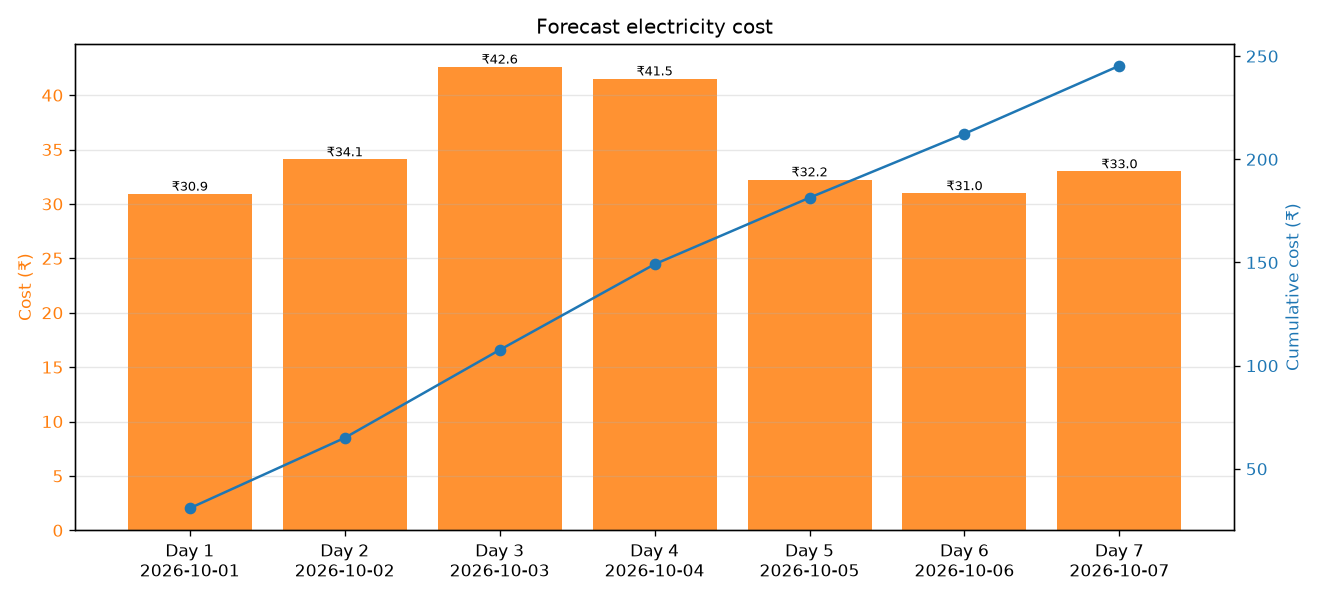

In [75]:
Image(filename="../outputs/cost_forecast.png")

### Compare tariffs for the same forecast

The model predicts consumption; the tariff only changes the money. Here we
re-price the forecast under a flat rate and a typical slab tariff.

In [76]:
import sys
for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / "tariffs.py").exists():
        sys.path.append(str(_p))
        break
from tariffs import Tariff, compute_bill, parse_slabs

forecast_kwh = [d["kwh"] for d in cost["daily"]]

flat = Tariff(rate=7.0)
slab = Tariff(
    slabs=parse_slabs("0-100:3.5,100-200:4.5,200-400:6.5,400-100000:7"),
    fixed=50.0,
    tax_pct=5.0,
)

for name, t in (("flat Rs7/kWh", flat), ("slab + Rs50 + 5% tax", slab)):
    b = compute_bill(forecast_kwh, t)
    print(f"{name:>24}: Rs {b['total']:.2f}  ({b['total_kwh']:.1f} kWh)")

            flat Rs7/kWh: Rs 245.34  (35.0 kWh)
    slab + Rs50 + 5% tax: Rs 178.80  (35.0 kWh)


### Monthly & 3-month cost projection

`predict.py` rolls the model forward **autoregressively** (`--project-days`,
default 90) to estimate a monthly (30-day) and 3-month (90-day) bill. Long
horizons compound model error, so treat these as directional estimates.

 Monthly (30d):    131.7 kWh   Rs 921.93
 3-Month (90d):    365.5 kWh   Rs 2558.84


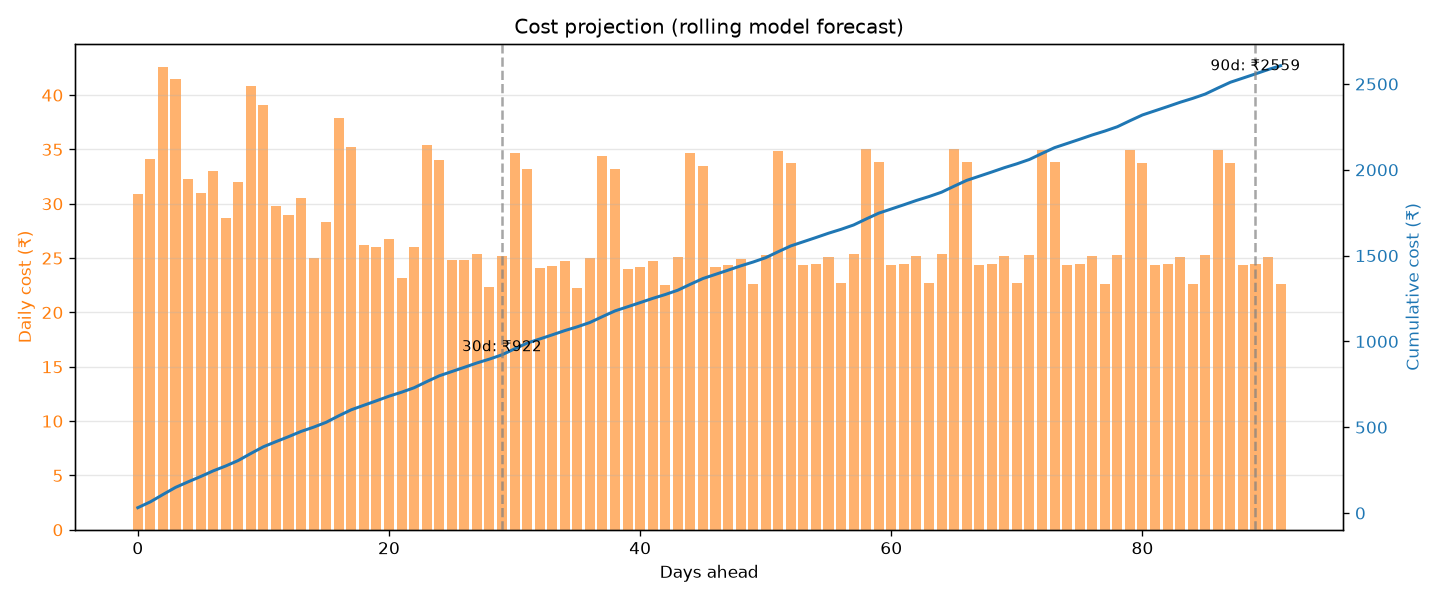

In [77]:
proj = json.loads(Path("../outputs/cost_summary.json").read_text())["projection"]
for label, key in (("Monthly (30d)", "monthly_30d"), ("3-Month (90d)", "three_month_90d")):
    p = proj[key]
    print(f"{label:>14}: {p['total_kwh']:8.1f} kWh   Rs {p['estimated_bill_inr']:.2f}")
Image(filename="../outputs/cost_projection.png")

In [78]:
proj_csv = pd.read_csv("../outputs/projection_90d.csv")
print("projected days:", len(proj_csv))
proj_csv.head()

projected days: 92


,date,projected_kwh,daily_cost_inr,cumulative_cost_inr
0,2026-10-01,4.417,30.92,30.92
1,2026-10-02,4.870,34.09,65.01
2,2026-10-03,6.087,42.61,107.62
3,2026-10-04,5.931,41.52,149.14
4,2026-10-05,4.606,32.24,181.38


### Downloadable Excel report

A single multi-sheet workbook (`Summary`, `Forecast`, `Projection`,
`Evaluation`, `Tariff`) is assembled from the pipeline outputs and offered
for download.

In [79]:
import sys
for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / "report.py").exists():
        sys.path.append(str(_p))
        break
from report import build_excel
from IPython.display import FileLink, display

xlsx = build_excel("../outputs", "../outputs/bijli_report.xlsx")
print("Workbook:", xlsx.resolve())
with pd.ExcelFile(xlsx) as xl:
    print("Sheets:", xl.sheet_names)
    display(xl.parse("Summary"))
display(FileLink(str(xlsx)))

Workbook: /home/mikey2006/CODING/AIML/LEARNING/NEURAL NETWORKS/bijli-predict-ai/outputs/bijli_report.xlsx
Sheets: ['Summary', 'Forecast', 'Projection', 'Evaluation', 'Tariff']


,Item,Value
0,Generated,2026-10-14 15:19
1,Model,GRU
2,Tariff,₹7/kWh (flat)
3,NaN,NaN
4,7-day forecast (kWh),35.05
5,7-day estimated bill (INR),245.34
6,Monthly 30d (kWh),131.7
7,Monthly 30d bill (INR),921.93
8,3-Month 90d (kWh),365.55
9,3-Month 90d bill (INR),2558.84


/home/mikey2006/CODING/AIML/LEARNING/NEURAL NETWORKS/bijli-predict-ai/outputs/bijli_report.xlsx